# Clustering practice

[Contents]

(1) K-mean Clustering  
(2) Hierarchical Clustering(Agglomerative)  
(3) DBSCAN  
(4) 데이터셋에 따른 성과비교 + 시각화(Dendrogram)
  
    
[Data]  
Synthetic datasets by scikit-learn   
https://scikit-learn.org/stable/datasets/sample_generators.html  


[Task]
주어진 판매 데이터를 활용하여 Segmentation(고객 세분화) 진행해보기
 - 적절한 method를 선택하여 Clustering
 - Cluster별 분석을 통해 Profiling 분석(고객특징 분석)  

[Data]  
Wholesale customers Data set  
https://archive.ics.uci.edu/dataset/292/wholesale+customers

[Note]

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform
import warnings
warnings.filterwarnings('ignore')
sns.set_style("whitegrid")


### Comparison of Clustering Methods

1. 합성 데이터 생성

In [ ]:
# 데이터 생성
print("=== 데이터셋 생성 ===")
np.random.seed(42)

# 1.구형 클러스터 데이터(Blob)
X_blobs, y_blobs = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=42)

# 2.초승달 모양 데이터(Moon)
X_moons, y_moons = make_moons(n_samples=300, noise=0.1, random_state=42)

# 데이터 표준화
scaler = StandardScaler()
X_blobs_scaled = scaler.fit_transform(X_blobs)
X_moons_scaled = scaler.fit_transform(X_moons)


=== 데이터셋 생성 ===


2. 클러스터링 평가 함수

In [ ]:

# Dunn Index 함수
def dunn_index(X, labels):
    """Dunn Index function"""
    unique_labels = np.unique(labels)
    if len(unique_labels) <= 1:
        return 0

    distances = pdist(X)
    distance_matrix = squareform(distances)

    # 클러스터 간 최소 거리
    min_inter_cluster = float('inf')
    for i in range(len(unique_labels)):
        for j in range(i+1, len(unique_labels)):
            cluster_i = X[labels == unique_labels[i]]
            cluster_j = X[labels == unique_labels[j]]

            min_dist = float('inf')
            for point_i in cluster_i:
                for point_j in cluster_j:
                    dist = np.linalg.norm(point_i - point_j)
                    min_dist = min(min_dist, dist)
            min_inter_cluster = min(min_inter_cluster, min_dist)

    # 클러스터 내 최대 거리
    max_intra_cluster = 0
    for label in unique_labels:
        cluster_points = X[labels == label]
        if len(cluster_points) > 1:
            cluster_distances = pdist(cluster_points)
            max_intra_cluster = max(max_intra_cluster, np.max(cluster_distances))

    return min_inter_cluster / max_intra_cluster if max_intra_cluster > 0 else 0

# 평가 함수
def evaluate_clustering(X, labels, method_name):
    """클러스터링 결과 평가"""
    # 노이즈 포인트 제외 (DBSCAN의 경우 -1 라벨)
    mask = labels != -1
    X_clean = X[mask]
    labels_clean = labels[mask]

    if len(np.unique(labels_clean)) <= 1:
        print(f"{method_name} - 클러스터가 1개 이하로 평가 불가")
        return None, None, None

    dunn = dunn_index(X_clean, labels_clean)
    calinski = calinski_harabasz_score(X_clean, labels_clean)
    silhouette = silhouette_score(X_clean, labels_clean)

    print(f"{method_name} 클러스터링 평가:")
    print(f"  Dunn Index: {dunn:.3f} ")
    print(f"  Calinski-Harabasz Index: {calinski:.3f} ")
    print(f"  Silhouette Score: {silhouette:.3f} ")
    print()

    return dunn, calinski, silhouette


3. 클러스터수 결정을 위한 Elbow Method

In [ ]:
# Elbow Method 함수
def elbow_method(X, max_k=10, title="Elbow Method"):
    inertias = []
    K_range = range(1, max_k+1)

    for k in K_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)

    plt.figure(figsize=(8, 4))
    plt.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
    plt.xlabel('Number of Clusters (k)', fontsize=12)
    plt.ylabel('Inertia', fontsize=12)
    plt.title(f'{title}', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.xticks(K_range)
    plt.tight_layout()
    plt.show()

    return inertias

4. 클러스터링 시각화(덴드로그램 포함)

In [ ]:

# 덴드로그램 함수
def plot_dendrogram(X, title):
    plt.figure(figsize=(8, 4))
    linkage_matrix = linkage(X, method='ward')
    dendrogram(linkage_matrix, truncate_mode='level', p=4,
               leaf_rotation=90, leaf_font_size=10)
    plt.title(f'Dendrogram - {title}', fontsize=14, fontweight='bold')
    plt.xlabel('Sample Index', fontsize=12)
    plt.ylabel('Distance', fontsize=12)
    plt.tight_layout()
    plt.show()

# 클러스터링 결과 시각화 함수
def plot_clustering_results(X, algorithms_results, original_labels, data_name):
    """클러스터링 결과를 시각화"""
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    fig.suptitle(f'Clustering Results - {data_name}', fontsize=16, fontweight='bold')

    # Original data
    axes[0].scatter(X[:, 0], X[:, 1], c='gray', cmap='viridis', s=30, alpha=0.7)
    axes[0].set_title('Original Data', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Feature 1', fontsize=9)
    axes[0].set_ylabel('Feature 2', fontsize=9)
    axes[0].grid(True, alpha=0.3)

    # Clustering results
    titles = ['K-Means', 'Hierarchical', 'DBSCAN']

    for i, (title, labels) in enumerate(algorithms_results):
        ax = axes[i + 1]
        scatter = ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=30, alpha=0.7)
        ax.set_title(f'{title}', fontsize=11, fontweight='bold')
        ax.set_xlabel('Feature 1', fontsize=9)
        ax.set_ylabel('Feature 2', fontsize=9)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# 클러스터별 통계 출력 함수
def print_cluster_stats(algorithms_results, data_name):
    """클러스터 개수 및 노이즈 포인트 통계 출력"""
    print(f"=== {data_name} 클러스터 정보 ===")
    for name, labels in algorithms_results:
        unique_labels = np.unique(labels)
        n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
        n_noise = np.sum(labels == -1) if -1 in unique_labels else 0
        print(f"{name}: {n_clusters}개 클러스터, {n_noise}개 Noise")
    print()

5. Experiment 1 - BLOB Data: Comparison of Clustering Methods

Elbow Method (Blob)
- 최적의 클러스터 수 탐색 - 기울기가 급격히 완만해지는 지점


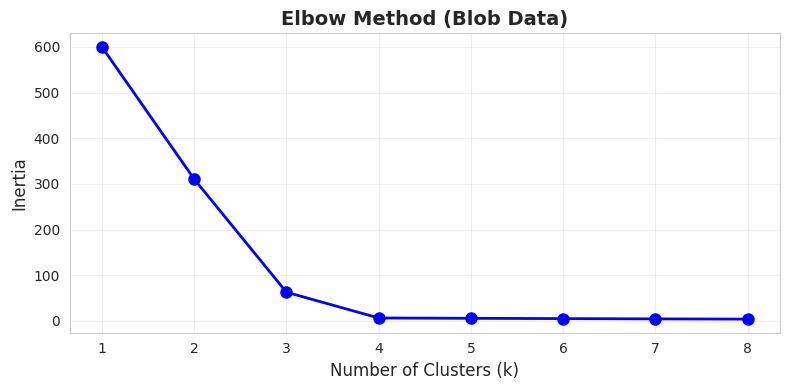

Dendrogram (Blob)


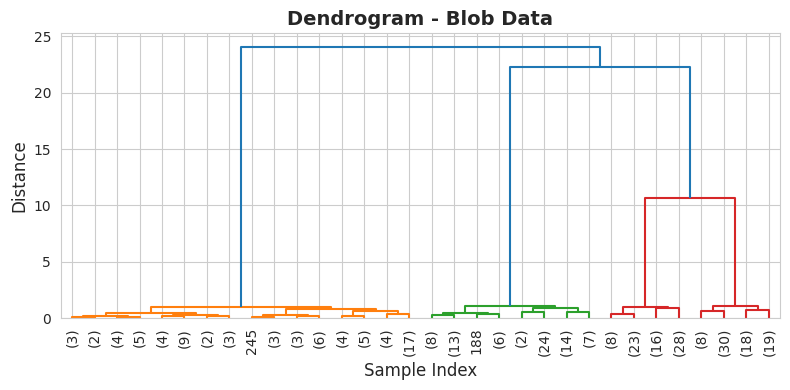

In [ ]:
# Elbow Method
print("Elbow Method (Blob)")
print("- 최적의 클러스터 수 탐색 - 기울기가 급격히 완만해지는 지점")
elbow_method(X_blobs_scaled, max_k=8, title="Elbow Method (Blob Data)")

# Dendrogram
print("Dendrogram (Blob)")
plot_dendrogram(X_blobs_scaled, "Blob Data")

클러스터링 실행 (Blob)


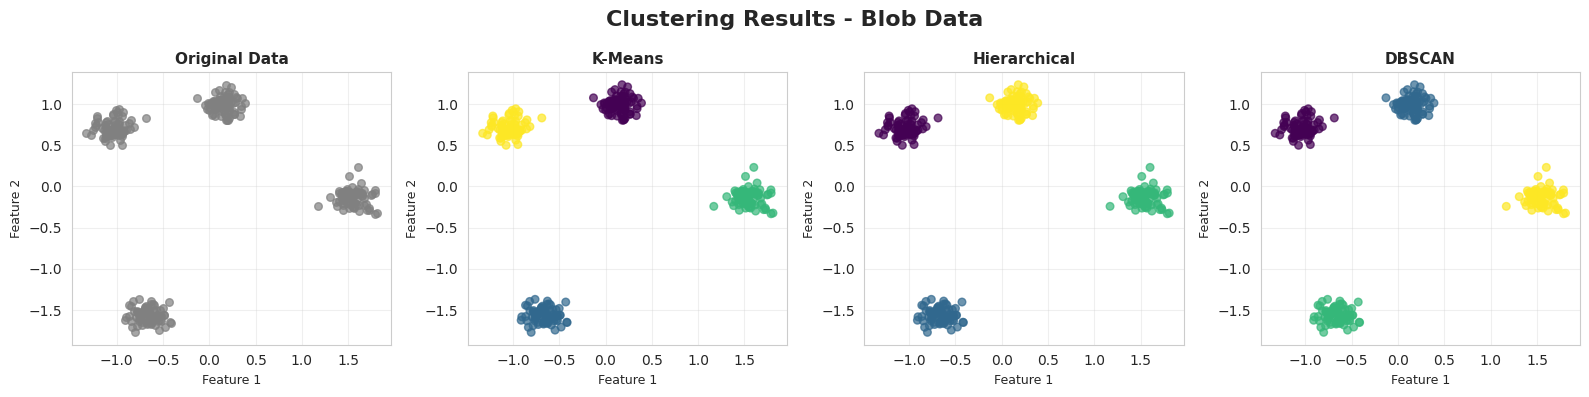

=== Blob Data 클러스터 정보 ===
K-Means: 4개 클러스터, 0개 Noise
Hierarchical: 4개 클러스터, 0개 Noise
DBSCAN: 4개 클러스터, 0개 Noise

성능 평가 (Blob)
K-Means (Blob) 클러스터링 평가:
  Dunn Index: 0.916 
  Calinski-Harabasz Index: 9129.065 
  Silhouette Score: 0.880 

Hierarchical (Blob) 클러스터링 평가:
  Dunn Index: 0.916 
  Calinski-Harabasz Index: 9129.065 
  Silhouette Score: 0.880 

DBSCAN (Blob) 클러스터링 평가:
  Dunn Index: 0.916 
  Calinski-Harabasz Index: 9129.065 
  Silhouette Score: 0.880 



(np.float64(0.9159222359410192),
 np.float64(9129.065187886943),
 np.float64(0.879591338894901))

In [ ]:
print("클러스터링 실행 (Blob)")

# K-Means
kmeans_blobs = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels_blobs = kmeans_blobs.fit_predict(X_blobs_scaled)

# Hierarchical
hierarchical_blobs = AgglomerativeClustering(n_clusters=4, linkage='ward')
hierarchical_labels_blobs = hierarchical_blobs.fit_predict(X_blobs_scaled)

# DBSCAN
dbscan_blobs = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels_blobs = dbscan_blobs.fit_predict(X_blobs_scaled)

# 결과 시각화
blob_results = [
    ('K-Means', kmeans_labels_blobs),
    ('Hierarchical', hierarchical_labels_blobs),
    ('DBSCAN', dbscan_labels_blobs)
]

plot_clustering_results(X_blobs_scaled, blob_results, y_blobs, "Blob Data")

# 클러스터 정보
print_cluster_stats(blob_results, "Blob Data")

# 성능 평가
print("성능 평가 (Blob)")
evaluate_clustering(X_blobs_scaled, kmeans_labels_blobs, "K-Means (Blob)")
evaluate_clustering(X_blobs_scaled, hierarchical_labels_blobs, "Hierarchical (Blob)")
evaluate_clustering(X_blobs_scaled, dbscan_labels_blobs, "DBSCAN (Blob)")


6. Experiment 2 - Moon Data: Comparison of Clustering Methods

Elbow Method (Moon)


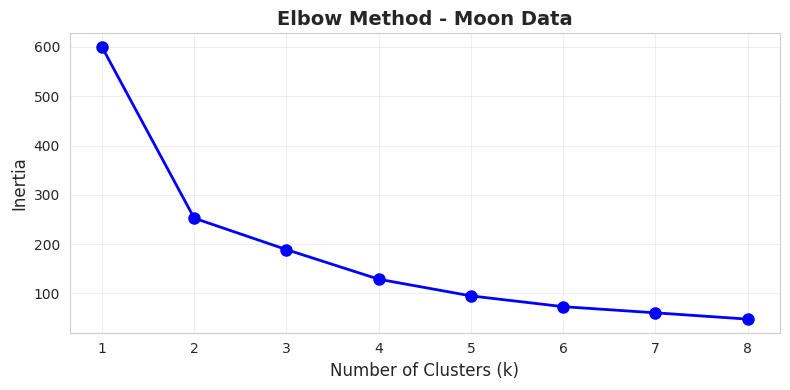

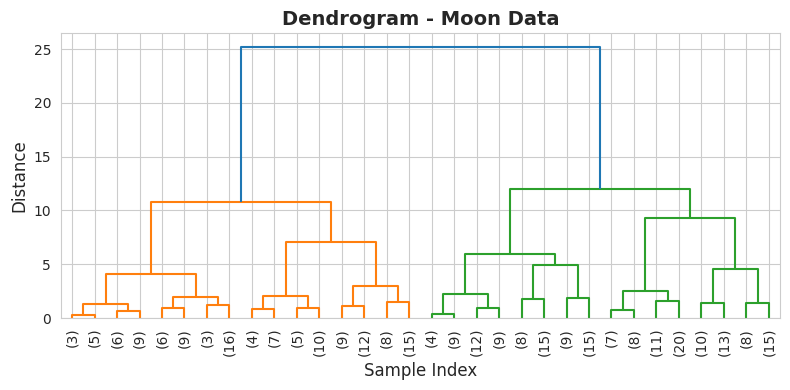

In [ ]:
# Elbow Method
print("Elbow Method (Moon)")
elbow_method(X_moons_scaled, max_k=8, title="Elbow Method - Moon Data")

# Dendrogram
plot_dendrogram(X_moons_scaled, "Moon Data")


클러스터링 실행 (Moon)


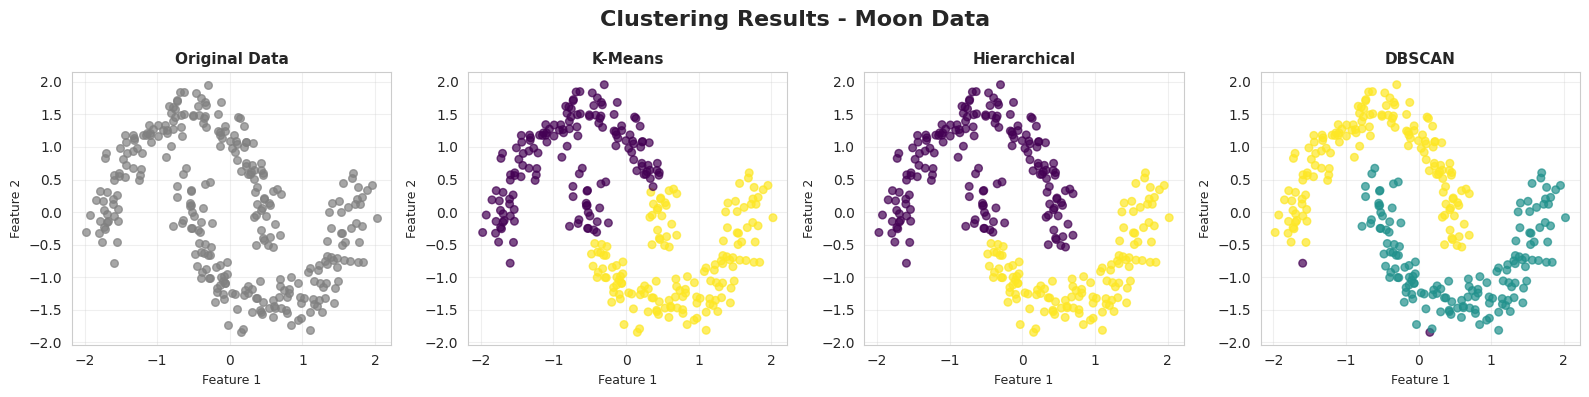

=== Moon Data 클러스터 정보 ===
K-Means: 2개 클러스터, 0개 Noise
Hierarchical: 2개 클러스터, 0개 Noise
DBSCAN: 2개 클러스터, 2개 Noise

K-Means (Moon) 클러스터링 평가:
  Dunn Index: 0.030 
  Calinski-Harabasz Index: 409.607 
  Silhouette Score: 0.491 

Hierarchical (Moon) 클러스터링 평가:
  Dunn Index: 0.058 
  Calinski-Harabasz Index: 335.133 
  Silhouette Score: 0.448 

DBSCAN (Moon) 클러스터링 평가:
  Dunn Index: 0.109 
  Calinski-Harabasz Index: 251.643 
  Silhouette Score: 0.376 



(np.float64(0.10859013652887294),
 np.float64(251.6427781189682),
 np.float64(0.3763520621462321))

In [ ]:
print("클러스터링 실행 (Moon)")

# K-Means
kmeans_moons = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels_moons = kmeans_moons.fit_predict(X_moons_scaled)

# Hierarchical
hierarchical_moons = AgglomerativeClustering(n_clusters=2, linkage='ward')
hierarchical_labels_moons = hierarchical_moons.fit_predict(X_moons_scaled)

# DBSCAN
dbscan_moons = DBSCAN(eps=0.3, min_samples=5)
dbscan_labels_moons = dbscan_moons.fit_predict(X_moons_scaled)

# 결과 시각화
moon_results = [
    ('K-Means', kmeans_labels_moons),
    ('Hierarchical', hierarchical_labels_moons),
    ('DBSCAN', dbscan_labels_moons)
]

plot_clustering_results(X_moons_scaled, moon_results, y_moons, "Moon Data")

# 클러스터 정보
print_cluster_stats(moon_results, "Moon Data")

# 성능 평가
evaluate_clustering(X_moons_scaled, kmeans_labels_moons, "K-Means (Moon)")
evaluate_clustering(X_moons_scaled, hierarchical_labels_moons, "Hierarchical (Moon)")
evaluate_clustering(X_moons_scaled, dbscan_labels_moons, "DBSCAN (Moon)")

### Task: Segmentation(고객 세분화)  

- 8개 변수를 활용하여 클러스터링+프로파일링 진행하기


In [ ]:
!pip install ucimlrepo

In [1]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from ucimlrepo import fetch_ucirepo
import pandas as pd

# UCI에서 데이터 불러오기
wholesale_customers = fetch_ucirepo(id=292)

X = wholesale_customers.data.features
y = wholesale_customers.data.targets

# Concatenate후 살펴보기
df = pd.concat([X, y], axis=1)

print(f"Data Shape: {df.shape}")
print(f"Categorical Variable: {X.select_dtypes(include=['object']).columns.tolist()}")
print(f"Info: {df.info()}")

print(f"{df.head(5)}")


Data Shape: (440, 8)
Categorical Variable: []
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Fresh             440 non-null    int64
 2   Milk              440 non-null    int64
 3   Grocery           440 non-null    int64
 4   Frozen            440 non-null    int64
 5   Detergents_Paper  440 non-null    int64
 6   Delicassen        440 non-null    int64
 7   Region            440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB
Info: None
   Channel  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen  Region
0        2  12669  9656     7561     214              2674        1338       3
1        2   7057  9810     9568    1762              3293        1776       3
2        2   6353  8808     7684    2405              3516        7844       3
3        1  13265  1196     4221    6404     

---
# 고객 세분화 (Customer Segmentation)

**목표:** 도매업체 고객 440명을 **비슷한 구매 패턴끼리** 묶고, 각 그룹이 어떤 고객인지 설명한다.

**데이터:** 고객 1명 = 1년간 6개 품목에 쓴 돈

| 컬럼 | 뜻 |
| --- | --- |
| Fresh | 신선식품 |
| Milk | 유제품 |
| Grocery | 식료품 |
| Frozen | 냉동식품 |
| Detergents_Paper | 세제·종이류(생활용품) |
| Delicassen | 델리(조리식품) |
| *Channel* | *1=식당/카페, 2=소매점* → **묶는 데 안 쓰고 나중에 검증용으로만 사용** |
| *Region* | *지역* → 위와 같음 |

**진행 순서**
1. 데이터 살펴보기 (전처리 결정)
2. 몇 개 그룹으로 나눌지(k) 정하기
3. 군집화 방법 3개 비교
4. 그룹별 고객 특성 분석 (Profiling)
5. 결과 정리

## 1. 데이터 살펴보기

먼저 **금액 분포**를 본다. 클러스터링은 "거리가 가까운 것끼리 묶는" 방식이라,
금액 분포가 이상하면 거리 계산부터 망가진다.

In [2]:
# ============================================================
# 1. 데이터 살펴보기
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score

# 실제로 묶는 데 사용할 6개 품목 (Channel, Region 은 제외)
SPEND = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]

print("=== 품목별 지출 분포 ===")
print(pd.DataFrame({
    "중앙값": df[SPEND].median().round(0),      # 한가운데 고객이 쓰는 돈
    "최대":   df[SPEND].max(),                  # 제일 많이 쓰는 고객
    "최대÷중앙값": (df[SPEND].max() / df[SPEND].median()).round(0),
}).to_string())

print("\n[문제] 최대값이 중앙값의 13~50배다.")
print("       예: Detergents_Paper 는 보통 816원인데 최대 40,827원.")
print("       이 상태로 거리를 재면 '큰손 몇 명' 이 거리를 다 차지해버린다.")
print("\n[해결] 로그(log)를 씌운다.")
print("       1,000 -> 10,000 과 10,000 -> 100,000 은 둘 다 '10배' 인데,")
print("       그냥 빼면 9,000 과 90,000 이라 뒤쪽만 크게 보인다.")
print("       로그를 씌우면 둘 다 같은 크기의 차이가 된다. = '몇 배 차이' 로 거리를 잼")

=== 품목별 지출 분포 ===
                     중앙값      최대  최대÷중앙값
Fresh             8504.0  112151    13.0
Milk              3627.0   73498    20.0
Grocery           4756.0   92780    20.0
Frozen            1526.0   60869    40.0
Detergents_Paper   816.0   40827    50.0
Delicassen         966.0   47943    50.0

[문제] 최대값이 중앙값의 13~50배다.
       예: Detergents_Paper 는 보통 816원인데 최대 40,827원.
       이 상태로 거리를 재면 '큰손 몇 명' 이 거리를 다 차지해버린다.

[해결] 로그(log)를 씌운다.
       1,000 -> 10,000 과 10,000 -> 100,000 은 둘 다 '10배' 인데,
       그냥 빼면 9,000 과 90,000 이라 뒤쪽만 크게 보인다.
       로그를 씌우면 둘 다 같은 크기의 차이가 된다. = '몇 배 차이' 로 거리를 잼


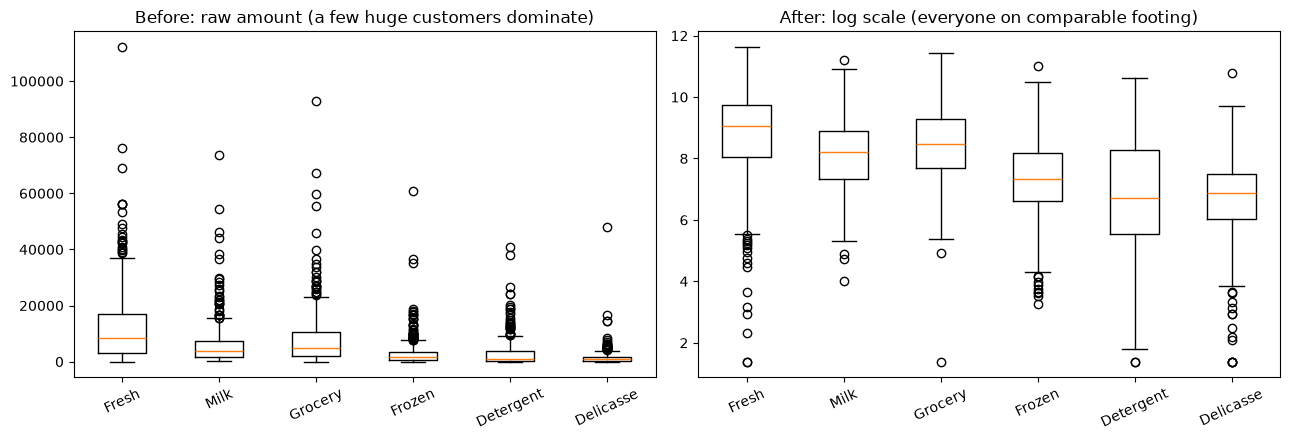

준비 완료: 440명 x 6개 품목


In [3]:
# ============================================================
# [그림 1] 로그를 씌우기 전과 후
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].boxplot([df[c] for c in SPEND])
ax[0].set_xticks(range(1, 7)); ax[0].set_xticklabels([c[:9] for c in SPEND], rotation=25)
ax[0].set_title("Before: raw amount (a few huge customers dominate)")

ax[1].boxplot([np.log1p(df[c]) for c in SPEND])
ax[1].set_xticks(range(1, 7)); ax[1].set_xticklabels([c[:9] for c in SPEND], rotation=25)
ax[1].set_title("After: log scale (everyone on comparable footing)")
plt.tight_layout(); plt.savefig("seg_fig1_log.png", dpi=120, bbox_inches="tight"); plt.show()

# 앞으로 사용할 데이터: 로그 씌우고 -> 6개 품목의 단위를 맞춤(표준화)
X = StandardScaler().fit_transform(np.log1p(df[SPEND]))
print(f"준비 완료: {X.shape[0]}명 x {X.shape[1]}개 품목")

In [4]:
# ============================================================
# 1-2. 로그를 안 씌우면 어떻게 되나? (근거)
# ============================================================
from sklearn.metrics import silhouette_score
RAW = StandardScaler().fit_transform(df[SPEND])      # 로그 없이 표준화만

print(f"{'k':>2} | {'원척도 실루엣':>10} {'그룹 크기':>22} | {'로그변환 실루엣':>12} {'그룹 크기':>24}")
print("-" * 82)
for k in (2, 3, 4):
    a = KMeans(k, random_state=42, n_init=10).fit_predict(RAW)
    b = KMeans(k, random_state=42, n_init=10).fit_predict(X)
    print(f"{k:>2} | {silhouette_score(RAW,a):10.3f} {str(sorted(np.bincount(a).tolist(),reverse=True)):>22}"
          f" | {silhouette_score(X,b):12.3f} {str(sorted(np.bincount(b).tolist(),reverse=True)):>24}")

print("\n[해석] 로그를 안 씌우면 실루엣이 0.55 로 훨씬 높다. 그런데 그룹을 열어보면")
print("       389명 한 덩어리 + 51명, k=3 에서는 2명짜리 그룹까지 생긴다.")
print("       점수가 높은 이유는 '이상치 몇 명을 따로 떼어냈기' 때문이지 세분화가 아니다.")
print("       -> 점수만 보고 고르면 안 되는 첫 번째 증거.")

 k |    원척도 실루엣                  그룹 크기 |     로그변환 실루엣                    그룹 크기
----------------------------------------------------------------------------------


 2 |      0.547              [389, 51] |        0.290               [252, 188]
 3 |      0.548           [393, 45, 2] |        0.259           [213, 147, 80]
 4 |      0.348      [315, 110, 10, 5] |        0.188      [132, 129, 118, 61]

[해석] 로그를 안 씌우면 실루엣이 0.55 로 훨씬 높다. 그런데 그룹을 열어보면
       389명 한 덩어리 + 51명, k=3 에서는 2명짜리 그룹까지 생긴다.
       점수가 높은 이유는 '이상치 몇 명을 따로 떼어냈기' 때문이지 세분화가 아니다.
       -> 점수만 보고 고르면 안 되는 첫 번째 증거.


## 2. 몇 개 그룹으로 나눌까? (k 정하기)

`K-Means` 는 **"몇 개로 나눌지(k)를 사람이 정해줘야"** 하는 방법이다.
정답이 없으므로 두 가지를 보고 정한다.

| 방법 | 뜻 | 보는 법 |
| --- | --- | --- |
| **Elbow** | 그룹 안에서 얼마나 뭉쳐있나 | 그래프가 **꺾이는 지점** |
| **Silhouette** | 내 그룹과는 가깝고 옆 그룹과는 먼가 (−1~1) | 높을수록 좋음 |

**단, 점수만 보면 안 된다.** 그룹 크기도 반드시 같이 본다.

In [5]:
# ============================================================
# 2. k(그룹 수) 정하기
# ============================================================
rows, inertia = [], []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(km.inertia_)                       # Elbow 용
    size = np.bincount(km.labels_)                    # 각 그룹 인원수
    rows.append({
        "k": k,
        "Silhouette": round(silhouette_score(X, km.labels_), 3),
        "가장 큰 그룹 비중": f"{size.max()/len(X)*100:.0f}%",
        "가장 작은 그룹": size.min(),
        "그룹별 인원": str(sorted(size.tolist(), reverse=True)),
    })
T = pd.DataFrame(rows)
print(T.to_string(index=False))

print("\n[읽는 법]")
print(" - Silhouette 는 k=2 가 제일 높다. 하지만 그때 그룹은 [252, 188] 로 2개뿐이다.")
print("   이건 '식당 vs 소매점' 이라는, Channel 컬럼에 이미 있는 정보다. 새로울 게 없다.")
print(" - k=8 은 13명짜리 그룹이 생긴다. 13명 대상으로 마케팅을 할 수는 없다.")
print(" - k=4 는 [132, 129, 118, 61] 로 고르게 나뉘고, 뒤에서 보듯 특징도 뚜렷하다.")
print("\n=> k = 4 로 결정")
K = 4

 k  Silhouette 가장 큰 그룹 비중  가장 작은 그룹                            그룹별 인원
 2       0.290        57%       188                        [252, 188]
 3       0.259        48%        80                    [213, 147, 80]
 4       0.188        30%        61               [132, 129, 118, 61]
 5       0.192        23%        54            [100, 100, 96, 90, 54]
 6       0.201        26%        20        [114, 101, 99, 55, 51, 20]
 7       0.196        27%        20     [118, 89, 84, 48, 41, 40, 20]
 8       0.185        23%        13 [103, 83, 72, 49, 45, 45, 30, 13]

[읽는 법]
 - Silhouette 는 k=2 가 제일 높다. 하지만 그때 그룹은 [252, 188] 로 2개뿐이다.
   이건 '식당 vs 소매점' 이라는, Channel 컬럼에 이미 있는 정보다. 새로울 게 없다.
 - k=8 은 13명짜리 그룹이 생긴다. 13명 대상으로 마케팅을 할 수는 없다.
 - k=4 는 [132, 129, 118, 61] 로 고르게 나뉘고, 뒤에서 보듯 특징도 뚜렷하다.

=> k = 4 로 결정


In [6]:
# ============================================================
# 2-2. k=4 를 고른 근거 (안정성 + Channel 비교)
# ============================================================
from sklearn.metrics import adjusted_rand_score

print(f"{'k':>2} | {'안정성':>7} | {'Channel 과 일치도':>15} | 메모")
print("-" * 60)
for k in range(2, 7):
    base = KMeans(k, random_state=42, n_init=10).fit(X)
    rng = np.random.RandomState(0)          # k 마다 같은 조건으로 비교
    s = []
    for b in range(20):
        idx = rng.choice(len(X), int(len(X) * 0.9), replace=False)
        lb2 = KMeans(k, random_state=b, n_init=10).fit_predict(X[idx])
        s.append(adjusted_rand_score(base.labels_[idx], lb2))
    ch = adjusted_rand_score(df["Channel"].values, base.labels_)
    memo = "Channel 을 그대로 재발견 -> 새 정보 없음" if ch > 0.45 else ""
    print(f"{k:>2} | {np.mean(s):7.3f} | {ch:15.3f} | {memo}")

print("""
[읽는 법]
  안정성        : 데이터의 90%만 뽑아 다시 묶었을 때 원래 결과와 얼마나 같은가 (1.0 = 완전 동일)
  Channel 일치도 : 결과가 이미 데이터에 있는 Channel 컬럼과 얼마나 같은가

[해석]
  안정성만 보면 k=2 가 제일 높다(0.97). 그런데 k=2 는 Channel 일치도가 0.51 로,
  '식당 vs 소매점' 이라는 이미 아는 정보를 다시 찾은 것에 불과하다.

  안정성은 k 가 커질수록 계속 떨어진다. 뚜렷한 꺾임점은 없지만
  k=5 부터는 0.76 이하로, 표본이 조금만 바뀌어도 결과가 달라진다.

  => 남는 후보는 k=3, k=4.
     둘 다 안정성은 쓸 만하므로, 최종 선택은 '프로파일이 더 뚜렷하게 갈리는가' 로 한다.
     k=3 의 213명 그룹을 열어보면 신선/냉동을 2~3배 쓰는 식당 84명과
     전 품목을 조금씩 쓰는 소규모 129명이 섞여 있다. 마케팅을 다르게 해야 하는
     두 집단이므로 이를 분리하는 k=4 를 선택.
""")

 k |     안정성 |   Channel 과 일치도 | 메모
------------------------------------------------------------


 2 |   0.965 |           0.514 | Channel 을 그대로 재발견 -> 새 정보 없음


 3 |   0.968 |           0.350 | 


 4 |   0.848 |           0.280 | 


 5 |   0.760 |           0.212 | 


 6 |   0.697 |           0.194 | 



[읽는 법]
  안정성        : 데이터의 90%만 뽑아 다시 묶었을 때 원래 결과와 얼마나 같은가 (1.0 = 완전 동일)
  Channel 일치도 : 결과가 이미 데이터에 있는 Channel 컬럼과 얼마나 같은가

[해석]
  안정성만 보면 k=2 가 제일 높다(0.97). 그런데 k=2 는 Channel 일치도가 0.51 로,
  '식당 vs 소매점' 이라는 이미 아는 정보를 다시 찾은 것에 불과하다.

  안정성은 k 가 커질수록 계속 떨어진다. 뚜렷한 꺾임점은 없지만
  k=5 부터는 0.76 이하로, 표본이 조금만 바뀌어도 결과가 달라진다.

  => 남는 후보는 k=3, k=4.
     둘 다 안정성은 쓸 만하므로, 최종 선택은 '프로파일이 더 뚜렷하게 갈리는가' 로 한다.
     k=3 의 213명 그룹을 열어보면 신선/냉동을 2~3배 쓰는 식당 84명과
     전 품목을 조금씩 쓰는 소규모 129명이 섞여 있다. 마케팅을 다르게 해야 하는
     두 집단이므로 이를 분리하는 k=4 를 선택.



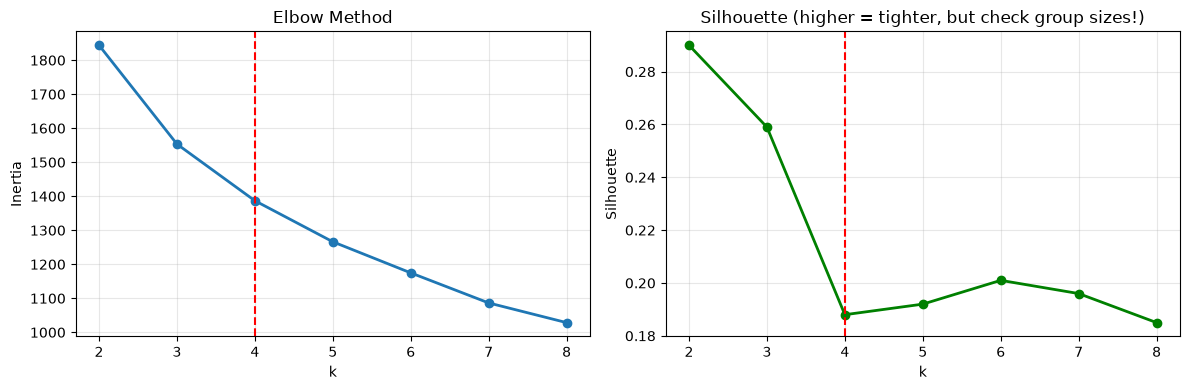

In [7]:
# ============================================================
# [그림 2] Elbow + Silhouette
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(2, 9), inertia, "o-", lw=2)
ax[0].axvline(K, ls="--", c="red"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[0].set_title("Elbow Method"); ax[0].grid(alpha=0.3)

ax[1].plot(T.k, T.Silhouette, "o-", lw=2, color="green")
ax[1].axvline(K, ls="--", c="red"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette")
ax[1].set_title("Silhouette (higher = tighter, but check group sizes!)"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig("seg_fig2_k.png", dpi=120, bbox_inches="tight"); plt.show()

## 3. 군집화 방법 3가지 비교

| 방법 | 어떻게 묶나 | 교재 |
| --- | --- | --- |
| **K-Means** | 중심점 k개를 찍고 → 가까운 쪽에 배정 → 중심 다시 계산, 반복 | p.47 |
| **Hierarchical** | 가까운 것부터 하나씩 합쳐 올라감 (나무 모양) | p.51 |
| **DBSCAN** | 빽빽하게 모인 곳만 그룹으로 인정, 나머지는 노이즈 | p.62 |

In [8]:
# ============================================================
# 3. 방법 3가지 비교
# ============================================================
results = {
    "K-Means":                KMeans(K, random_state=42, n_init=10).fit_predict(X),
    "Hierarchical (ward)":    AgglomerativeClustering(K, linkage="ward").fit_predict(X),
    "Hierarchical (average)": AgglomerativeClustering(K, linkage="average").fit_predict(X),
    "DBSCAN (eps=1.5)":       DBSCAN(eps=1.5, min_samples=5).fit_predict(X),
}

rows = []
for name, lab in results.items():
    ok = lab != -1                       # DBSCAN 의 -1 은 '노이즈(어디에도 안 속함)'
    n_grp = len(set(lab[ok]))
    sil = silhouette_score(X[ok], lab[ok]) if n_grp > 1 else np.nan
    rows.append({"방법": name, "그룹 수": n_grp,
                 "Silhouette": round(sil, 3) if n_grp > 1 else "평가불가",
                 "노이즈": int((~ok).sum()),
                 "그룹별 인원": str(sorted(np.bincount(lab[ok]).tolist(), reverse=True))})
print(pd.DataFrame(rows).to_string(index=False))

print("\n[결과 해석] ★ 이번 실습에서 가장 중요한 부분")
print(" - Hierarchical(average) 가 Silhouette 0.498 로 1등이다.")
print("   그런데 그룹을 열어보면 [437, 1, 1, 1] -> 440명 중 437명이 한 덩어리,")
print("   나머지 3명이 각각 혼자다. 점수는 1등인데 '세분화' 가 전혀 안 됐다.")
print(" - DBSCAN 은 이 데이터에서 그룹을 1개밖에 못 만든다.")
print("   빽빽한 곳과 성긴 곳의 구분이 없는 '하나의 덩어리' 라서 쪼갤 근거가 없다.")
print("   (노트북 앞부분 초승달 데이터에서는 DBSCAN 이 제일 잘했던 것과 정반대)")
print(" - K-Means 는 점수가 제일 낮지만 [132, 129, 118, 61] 로 고르게 나눈다.")
print("\n=> 점수가 아니라 '쓸 수 있는 결과인가' 로 K-Means 채택")
labels = results["K-Means"]
df["cluster"] = labels

                    방법  그룹 수 Silhouette  노이즈              그룹별 인원
               K-Means     4      0.188    0 [132, 129, 118, 61]
   Hierarchical (ward)     4      0.202    0  [208, 125, 54, 53]
Hierarchical (average)     4      0.498    0      [437, 1, 1, 1]
      DBSCAN (eps=1.5)     1       평가불가   41               [399]

[결과 해석] ★ 이번 실습에서 가장 중요한 부분
 - Hierarchical(average) 가 Silhouette 0.498 로 1등이다.
   그런데 그룹을 열어보면 [437, 1, 1, 1] -> 440명 중 437명이 한 덩어리,
   나머지 3명이 각각 혼자다. 점수는 1등인데 '세분화' 가 전혀 안 됐다.
 - DBSCAN 은 이 데이터에서 그룹을 1개밖에 못 만든다.
   빽빽한 곳과 성긴 곳의 구분이 없는 '하나의 덩어리' 라서 쪼갤 근거가 없다.
   (노트북 앞부분 초승달 데이터에서는 DBSCAN 이 제일 잘했던 것과 정반대)
 - K-Means 는 점수가 제일 낮지만 [132, 129, 118, 61] 로 고르게 나눈다.

=> 점수가 아니라 '쓸 수 있는 결과인가' 로 K-Means 채택


## 4. 그룹별 고객 특성 분석 (Profiling) ★

**여기가 이 과제의 핵심 결과물이다.** 묶는 것 자체보다 *"각 그룹이 어떤 고객인가"* 가 중요하다.

금액을 그대로 보면 감이 안 오므로 **전체 중앙값의 몇 배인지**로 바꿔서 본다.
(1.0배 = 평균적인 고객, 2.0배 = 두 배로 많이 씀)

In [9]:
# ============================================================
# 4. 그룹별 프로파일링
# ============================================================
prof  = df.groupby("cluster")[SPEND].median()      # 그룹별 중앙값
ratio = prof / df[SPEND].median()                  # 전체 중앙값 대비 몇 배인가

info = pd.DataFrame({"인원": df.groupby("cluster").size()})
info["비중"] = (info["인원"] / len(df) * 100).round(0).astype(int).astype(str) + "%"
# Channel 은 묶는 데 안 썼다. 결과가 말이 되는지 확인하는 용도로만 본다.
info["소매점 비율"] = (df.groupby("cluster")["Channel"]
                    .apply(lambda s: (s == 2).mean() * 100)).round(0).astype(int).astype(str) + "%"

print("=== 그룹별 실제 지출액 (중앙값) ===")
print(pd.concat([prof.round(0).astype(int), info], axis=1).to_string())
print("\n=== 전체 중앙값 대비 몇 배인가 (1.0 = 평균적인 고객) ===")
print(ratio.round(1).to_string())

이름 = {0: "생활용품 소매점  (신선/냉동 거의 안 삼)",
       1: "식당·외식업     (신선/냉동 대량)",
       2: "소규모 저활동   (전 품목 조금씩)",
       3: "대형 슈퍼마켓   (전 품목 대량)"}
print("\n=== 그룹 해석 ===")
for c in sorted(df["cluster"].unique()):
    r = ratio.loc[c].sort_values(ascending=False)
    print(f"\n[그룹 {c}] {이름.get(c,'')}  — {info.loc[c,'인원']}명({info.loc[c,'비중']}), "
          f"소매점 비율 {info.loc[c,'소매점 비율']}")
    print("   많이 씀: " + ", ".join(f"{k} {v:.1f}배" for k, v in r[r >= 1.5].items()))
    print("   적게 씀: " + ", ".join(f"{k} {v:.1f}배" for k, v in r[r <= 0.6].items()))

=== 그룹별 실제 지출액 (중앙값) ===
         Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen   인원   비중 소매점 비율
cluster                                                                             
0         1073  6964    10518     340              4508         295   61  14%    66%
1        17023  3086     3445    4324               529        1404  129  29%     5%
2         7814  1114     1820    1390               224         435  132  30%     1%
3         7832  8482    12272    1347              4644        1682  118  27%    80%

=== 전체 중앙값 대비 몇 배인가 (1.0 = 평균적인 고객) ===
         Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                            
0          0.1   1.9      2.2     0.2               5.5         0.3
1          2.0   0.9      0.7     2.8               0.6         1.5
2          0.9   0.3      0.4     0.9               0.3         0.5
3          0.9   2.3      2.6     0.9               5.7         1.7

=== 그룹 해석 ===



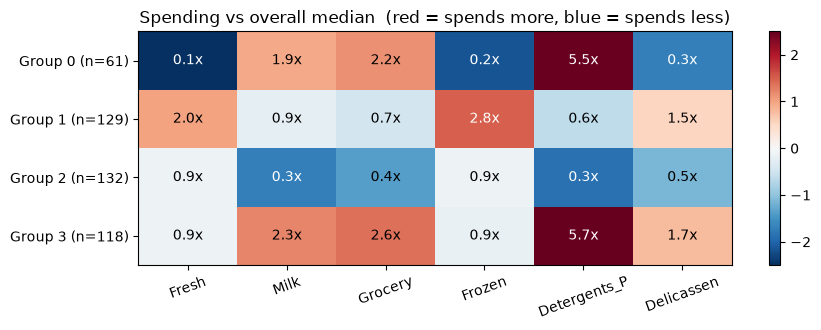

In [10]:
# ============================================================
# [그림 3] 프로파일 히트맵 — 제출물의 핵심 그림
# ============================================================
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(np.log2(ratio.values), cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(6)); ax.set_xticklabels([c[:12] for c in SPEND], rotation=20)
ax.set_yticks(range(K)); ax.set_yticklabels([f"Group {c} (n={info.loc[c,'인원']})" for c in ratio.index])
for i in range(K):
    for j in range(6):
        v = ratio.values[i, j]
        ax.text(j, i, f"{v:.1f}x", ha="center", va="center", fontsize=10,
                color="white" if abs(np.log2(v)) > 1.4 else "black")
ax.set_title("Spending vs overall median  (red = spends more, blue = spends less)")
plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig("seg_fig3_profile.png", dpi=120, bbox_inches="tight"); plt.show()

## 5. 결과 정리

In [11]:
# ============================================================
# 5. 최종 정리 — 이 셀 하나로 결과 전체 확인
# ============================================================
print("=" * 68)
print("  최종 모델")
print("=" * 68)
print(f"""
  전처리   : log(금액) -> 표준화        (큰손 몇 명이 거리를 독점하는 것 방지)
  입력     : {SPEND}
  제외     : Channel, Region            (검증용으로만 사용)
  방법     : K-Means, k={K}
  Silhouette : {silhouette_score(X, labels):.3f}
""")

print("=" * 68); print("  고객 세분화 결과"); print("=" * 68)
out = pd.DataFrame({
    "그룹": [f"{c}" for c in ratio.index],
    "고객 특성": [이름.get(c, "") for c in ratio.index],
    "인원": info["인원"].values,
    "비중": info["비중"].values,
    "소매점비율": info["소매점 비율"].values,
})
print(out.to_string(index=False))

print("\n" + "=" * 68); print("  이번 실습에서 배운 것"); print("=" * 68)
print("""
  1) 점수가 높다고 좋은 결과가 아니다
     Silhouette 1등(0.498)은 440명 중 437명을 한 덩어리로 묶은 결과였다.
     반드시 '그룹별 인원수' 를 함께 봐야 한다.

  2) 전처리가 방법 선택보다 중요했다
     로그를 씌우느냐 마느냐가 결과를 갈랐다.
     K-Means / Hierarchical / DBSCAN 중 무엇을 고르느냐보다 영향이 컸다.

  3) 데이터 모양에 따라 맞는 방법이 다르다
     DBSCAN 은 초승달 모양 데이터에서는 최고였지만,
     이 고객 데이터에서는 그룹을 1개밖에 못 만들었다.
""")

  최종 모델

  전처리   : log(금액) -> 표준화        (큰손 몇 명이 거리를 독점하는 것 방지)
  입력     : ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
  제외     : Channel, Region            (검증용으로만 사용)
  방법     : K-Means, k=4
  Silhouette : 0.188

  고객 세분화 결과
그룹                    고객 특성  인원  비중 소매점비율
 0 생활용품 소매점  (신선/냉동 거의 안 삼)  61 14%   66%
 1    식당·외식업     (신선/냉동 대량) 129 29%    5%
 2     소규모 저활동   (전 품목 조금씩) 132 30%    1%
 3      대형 슈퍼마켓   (전 품목 대량) 118 27%   80%

  이번 실습에서 배운 것

  1) 점수가 높다고 좋은 결과가 아니다
     Silhouette 1등(0.498)은 440명 중 437명을 한 덩어리로 묶은 결과였다.
     반드시 '그룹별 인원수' 를 함께 봐야 한다.

  2) 전처리가 방법 선택보다 중요했다
     로그를 씌우느냐 마느냐가 결과를 갈랐다.
     K-Means / Hierarchical / DBSCAN 중 무엇을 고르느냐보다 영향이 컸다.

  3) 데이터 모양에 따라 맞는 방법이 다르다
     DBSCAN 은 초승달 모양 데이터에서는 최고였지만,
     이 고객 데이터에서는 그룹을 1개밖에 못 만들었다.

